# Tech Challenge Fase 1 — Olist: crescimento, entrega e satisfação
**Tese:** a Olist cresceu rápido, mas o crescimento estagnou em 2018; o atraso na entrega derruba a nota dos clientes, e quase ninguém volta a comprar.

Convenções: período analisado jan/2017–ago/2018 (demais meses têm volume residual); receita = soma de `price` dos itens de pedidos **entregues**; recompra por `customer_unique_id`.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
RAW=Path('../data/raw'); FIG=Path('../reports/figuras'); FIG.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.figsize':(9,4.5),'axes.spines.top':False,'axes.spines.right':False,'font.size':11})
dt=['order_purchase_timestamp','order_approved_at','order_delivered_carrier_date','order_delivered_customer_date','order_estimated_delivery_date']
orders=pd.read_csv(RAW/'olist_orders_dataset.csv',parse_dates=dt)
items=pd.read_csv(RAW/'olist_order_items_dataset.csv')
reviews=pd.read_csv(RAW/'olist_order_reviews_dataset.csv')
cust=pd.read_csv(RAW/'olist_customers_dataset.csv',dtype={'customer_zip_code_prefix':str})
prods=pd.read_csv(RAW/'olist_products_dataset.csv')
trans=pd.read_csv(RAW/'product_category_name_translation.csv')
sellers=pd.read_csv(RAW/'olist_sellers_dataset.csv',dtype={'seller_zip_code_prefix':str})

## 1. Preparação e qualidade dos dados

In [2]:
print(orders.order_status.value_counts())
print('Nulos em orders:\n',orders.isna().sum()[lambda s:s>0])
# base analítica: pedidos entregues, com data de entrega, jan/2017-ago/2018
df=orders[(orders.order_status=='delivered')&orders.order_delivered_customer_date.notna()].copy()
df=df[(df.order_purchase_timestamp>='2017-01-01')&(df.order_purchase_timestamp<'2018-09-01')]
rev=items.groupby('order_id').agg(receita=('price','sum'),frete=('freight_value','sum'),itens=('order_item_id','count'))
nota=reviews.groupby('order_id').review_score.mean().rename('nota')   # alguns pedidos têm >1 avaliação
df=df.join(rev,on='order_id').join(nota,on='order_id').merge(cust,on='customer_id')
df['mes']=df.order_purchase_timestamp.dt.to_period('M')
df['dias_entrega']=(df.order_delivered_customer_date-df.order_purchase_timestamp).dt.days
df['dias_atraso']=np.ceil((df.order_delivered_customer_date-df.order_estimated_delivery_date).dt.total_seconds()/86400)  # fração de dia conta como 1 dia
df['atrasou']=df.dias_atraso>0
print(f'Base analítica: {len(df):,} pedidos | sem avaliação: {df.nota.isna().mean():.1%} | sem itens: {df.receita.isna().sum()}')

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
Nulos em orders:
 order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64


Base analítica: 96,203 pedidos | sem avaliação: 0.7% | sem itens: 0


## 2. Crescimento

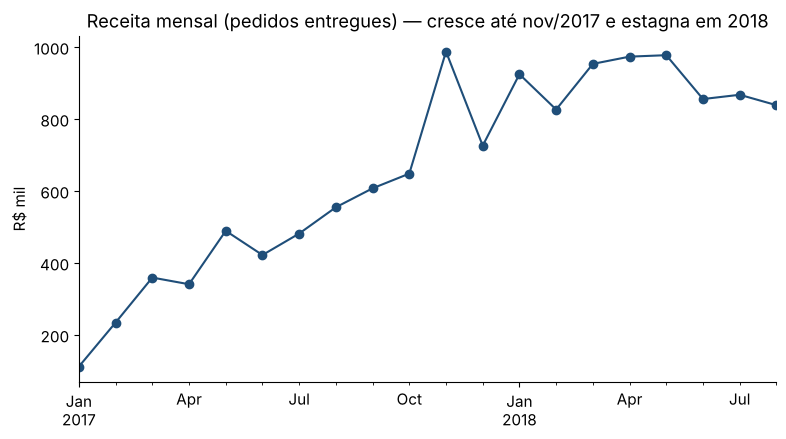

Receita total R$ 13,179,778 | pedidos 96,203 | ticket médio R$ 137 | frete = 16.6% da receita
1º semestre 2018 vs 1º semestre 2017: +182%
Média mensal jan-ago/2018: R$ 902,147 | pico nov/2017 (Black Friday): R$ 987,648


In [3]:
m=df.groupby('mes').agg(pedidos=('order_id','nunique'),receita=('receita','sum'))
m['ticket']=m.receita/m.pedidos
fig,ax=plt.subplots(); (m.receita/1e3).plot(ax=ax,marker='o',color='#1f4e79')
ax.set_title('Receita mensal (pedidos entregues) — cresce até nov/2017 e estagna em 2018'); ax.set_ylabel('R$ mil'); ax.set_xlabel('')
fig.savefig(FIG/'01_receita_mensal.png',dpi=150,bbox_inches='tight'); plt.show()
print('Receita total R$ {:,.0f} | pedidos {:,} | ticket médio R$ {:.0f} | frete = {:.1%} da receita'.format(df.receita.sum(),len(df),df.receita.sum()/len(df),df.frete.sum()/df.receita.sum()))
h1=m.loc['2017-01':'2017-06','receita'].sum(); h2=m.loc['2018-01':'2018-06','receita'].sum()
print(f'1º semestre 2018 vs 1º semestre 2017: {h2/h1-1:+.0%}')
print('Média mensal jan-ago/2018: R$ {:,.0f} | pico nov/2017 (Black Friday): R$ {:,.0f}'.format(m.loc['2018-01':,'receita'].mean(),m.loc['2017-11','receita']))

product_category_name_english
health_beauty            0.095
watches_gifts            0.089
bed_bath_table           0.079
sports_leisure           0.073
computers_accessories    0.068
furniture_decor          0.054
housewares               0.047
cool_stuff               0.047
auto                     0.044
garden_tools             0.036
Name: price, dtype: float64
Top 10 categorias = 63% da receita


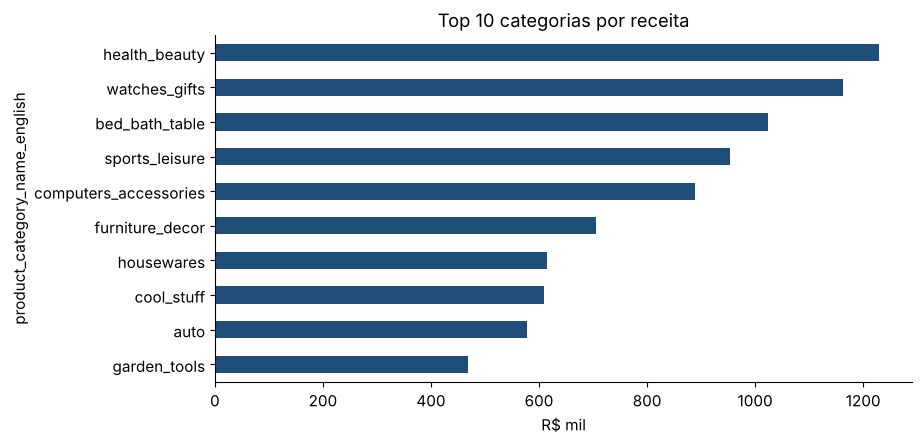

Vendedores: 2,945 | top 10% dos vendedores = 67% da receita


In [4]:
cat=items.merge(prods[['product_id','product_category_name']],on='product_id').merge(trans,on='product_category_name',how='left')
cat=cat[cat.order_id.isin(df.order_id)]
top=cat.groupby('product_category_name_english').price.sum().sort_values(ascending=False)
share=(top/top.sum())
print(share.head(10).round(3)); print('Top 10 categorias = {:.0%} da receita'.format(share.head(10).sum()))
fig,ax=plt.subplots(); (top.head(10)[::-1]/1e3).plot.barh(ax=ax,color='#1f4e79'); ax.set_xlabel('R$ mil'); ax.set_title('Top 10 categorias por receita')
fig.savefig(FIG/'02_top_categorias.png',dpi=150,bbox_inches='tight'); plt.show()
sel=items[items.order_id.isin(df.order_id)].groupby('seller_id').price.sum().sort_values(ascending=False)
print(f'Vendedores: {len(sel):,} | top 10% dos vendedores = {sel.head(int(len(sel)*.1)).sum()/sel.sum():.0%} da receita')

## 3. Logística

Atraso (entrega após a data estimada): 8.1% dos pedidos | prazo mediano de entrega: 10 dias


                pedidos  atraso  dias   nota     receita
customer_state                                          
AL                  396   0.240  22.0  3.852    78805.73
MA                  713   0.196  19.0  3.830   116305.12
PI                  475   0.160  16.0  3.994    84511.00
CE                 1273   0.154  18.0  3.938   218107.70
SE                  332   0.154  17.0  3.900    56288.74
BA                 3253   0.140  16.0  3.930   493339.26
RJ                12310   0.135  12.0  3.965  1751433.85
PA                  942   0.124  21.0  3.909   173382.99
ES                 1992   0.122  13.0  4.080   267783.66
MS                  701   0.116  13.0  4.160   115429.97
PB                  516   0.110  18.0  4.074   112536.92
RN                  470   0.109  16.0  4.142    81376.97
PE                 1587   0.108  15.0  4.082   250639.89
SC                 3537   0.098  13.0  4.134   504774.07
GO                 1950   0.082  13.0  4.102   281932.21
RS                 5327   0.072

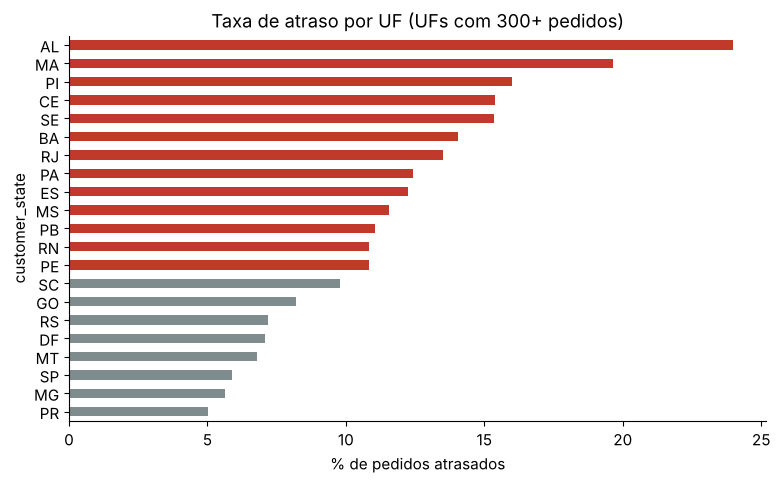

In [5]:
print(f'Atraso (entrega após a data estimada): {df.atrasou.mean():.1%} dos pedidos | prazo mediano de entrega: {df.dias_entrega.median():.0f} dias')
uf=df.groupby('customer_state').agg(pedidos=('order_id','size'),atraso=('atrasou','mean'),dias=('dias_entrega','median'),nota=('nota','mean'),receita=('receita','sum'))
uf=uf[uf.pedidos>=300].sort_values('atraso',ascending=False)
print(uf.round(3).to_string())
fig,ax=plt.subplots(figsize=(9,5)); (uf.atraso[::-1]*100).plot.barh(ax=ax,color=['#c0392b' if v>.10 else '#7f8c8d' for v in uf.atraso[::-1]])
ax.set_xlabel('% de pedidos atrasados'); ax.set_title('Taxa de atraso por UF (UFs com 300+ pedidos)')
fig.savefig(FIG/'03_atraso_por_uf.png',dpi=150,bbox_inches='tight'); plt.show()

## 4. Satisfação: o custo do atraso

            nota  pedidos  nota_baixa
faixa                                
No prazo   4.295    87902       0.092
1–3 dias   3.767     2635       0.191
4–7 dias   2.317     1773       0.613
8–15 dias  1.732     1917       0.784
>15 dias   1.727     1333       0.782


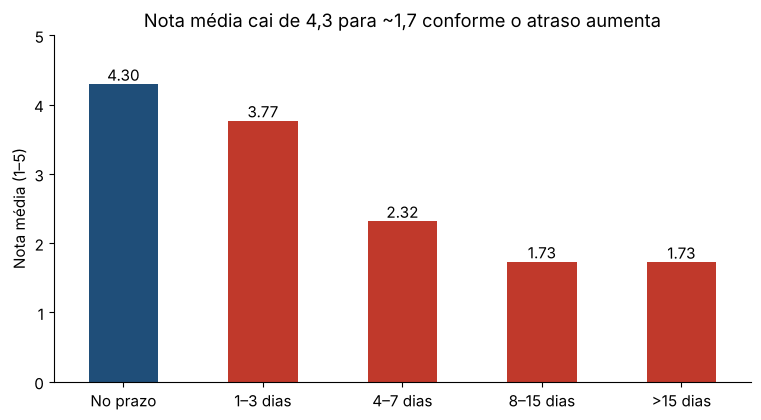

Nota média: no prazo 4.30 vs atrasado 2.57
Notas 1–2: no prazo 9% vs atrasado 54%
Atrasos explicam 34% das notas baixas (1–2) com apenas 8% dos pedidos


In [6]:
g=df.dropna(subset=['nota']).copy()
g['faixa']=pd.cut(g.dias_atraso,[-999,0,3,7,15,999],labels=['No prazo','1–3 dias','4–7 dias','8–15 dias','>15 dias'])
t=g.groupby('faixa',observed=True).agg(nota=('nota','mean'),pedidos=('order_id','size'),nota_baixa=('nota',lambda s:(s<=2).mean()))
print(t.round(3))
fig,ax=plt.subplots(); t.nota.plot.bar(ax=ax,color=['#1f4e79']+['#c0392b']*4,rot=0); ax.set_ylim(0,5); ax.set_ylabel('Nota média (1–5)')
ax.set_title('Nota média cai de 4,3 para ~1,7 conforme o atraso aumenta'); ax.set_xlabel('')
for i,v in enumerate(t.nota): ax.text(i,v+.05,f'{v:.2f}',ha='center')
fig.savefig(FIG/'04_nota_por_atraso.png',dpi=150,bbox_inches='tight'); plt.show()
print('Nota média: no prazo {:.2f} vs atrasado {:.2f}'.format(g[~g.atrasou].nota.mean(),g[g.atrasou].nota.mean()))
print('Notas 1–2: no prazo {:.0%} vs atrasado {:.0%}'.format((g[~g.atrasou].nota<=2).mean(),(g[g.atrasou].nota<=2).mean()))
print('Atrasos explicam {:.0%} das notas baixas (1–2) com apenas {:.0%} dos pedidos'.format(g[g.atrasou&(g.nota<=2)].shape[0]/g[g.nota<=2].shape[0],g.atrasou.mean()))

## 5. Retenção

In [7]:
d=df.sort_values('order_purchase_timestamp')
n=d.groupby('customer_unique_id').order_id.nunique()
print(f'Clientes únicos: {len(n):,} | recompra: {(n>1).mean():.1%}')
primeira=d.groupby('customer_unique_id').head(1).set_index('customer_unique_id'); primeira['recomprou']=n>1
print('Recompra por 1ª entrega atrasada?'); print(primeira.groupby('atrasou').recomprou.agg(['mean','size']).round(4))
primeira['nota_b']=pd.cut(primeira.nota,[0,2,3,5],labels=['1–2','3','4–5'])
print('Recompra por nota da 1ª compra'); print(primeira.groupby('nota_b',observed=True).recomprou.agg(['mean','size']).round(4))

Clientes únicos: 93,096 | recompra: 3.0%
Recompra por 1ª entrega atrasada?
           mean   size
atrasou               
False    0.0305  85502
True     0.0244   7594
Recompra por nota da 1ª compra
          mean   size
nota_b               
1–2     0.0276  11852
3       0.0300   7662
4–5     0.0303  72968


## 6. Impacto financeiro estimado (cenário)

In [8]:
atrasados=df[df.atrasou]
print(f'Receita em pedidos atrasados: R$ {atrasados.receita.sum():,.0f} ({atrasados.receita.sum()/df.receita.sum():.1%} da receita)')
# Cenário: reduzir o atraso nas UFs críticas (>10%) à média das demais
crit=uf[uf.atraso>.10].index; ok=df[~df.customer_state.isin(crit)]
meta=ok.atrasou.mean(); rec=df[df.customer_state.isin(crit)]
evitados=(rec.atrasou.mean()-meta)*len(rec)
print(f'UFs críticas ({len(crit)}): atraso médio {rec.atrasou.mean():.1%} vs {meta:.1%} nas demais')
print(f'Atrasos evitáveis no período: ~{evitados:,.0f} pedidos (~{evitados/ (df.order_purchase_timestamp.max()-df.order_purchase_timestamp.min()).days*365:,.0f}/ano)')
print('Impacto em nota: cada atraso evitado recupera ≈ {:.1f} ponto de nota'.format(g[~g.atrasou].nota.mean()-g[g.atrasou].nota.mean()))

Receita em pedidos atrasados: R$ 1,158,438 (8.8% da receita)
UFs críticas (13): atraso médio 13.6% vs 6.2% nas demais
Atrasos evitáveis no período: ~1,852 pedidos (~1,125/ano)


Impacto em nota: cada atraso evitado recupera ≈ 1.7 ponto de nota


## 7. Estatística descritiva do prazo de entrega
Tipos de variável (Aula 2): prazo em dias é **quantitativa contínua** (escala de razão); nota de 1 a 5 é **qualitativa ordinal**; UF é **qualitativa nominal**.
Tendência central e dispersão (Aulas 4 e 5): comparamos média, mediana, desvio-padrão e coeficiente de variação (CV).

Prazo de entrega (dias): média 12.5 | mediana 10.2 | desvio-padrão 9.5 | CV 0.76 | P90 23.1 | máximo 210 | assimetria 3.85
Média > mediana e assimetria positiva: poucos pedidos muito demorados puxam a média para cima, por isso usamos a mediana como prazo típico.
                pedidos  media  mediana  desvio  atraso    cv
customer_state                                               
SE                  332  21.44    17.93   16.77    0.15  0.78
PI                  475  19.44    16.28   14.73    0.16  0.76
PA                  942  23.76    21.07   13.16    0.12  0.55
CE                 1273  21.24    18.17   13.08    0.15  0.62
RN                  470  19.21    16.05   12.97    0.11  0.67
BA                 3253  19.33    16.91   11.70    0.14  0.60
RJ                12310  15.30    12.04   11.52    0.14  0.75
AL                  396  24.52    22.33   11.49    0.24  0.47
MA                  713  21.54    19.18   11.26    0.20  0.52
PE                 1587  18.45    15.70   10.96    0.11

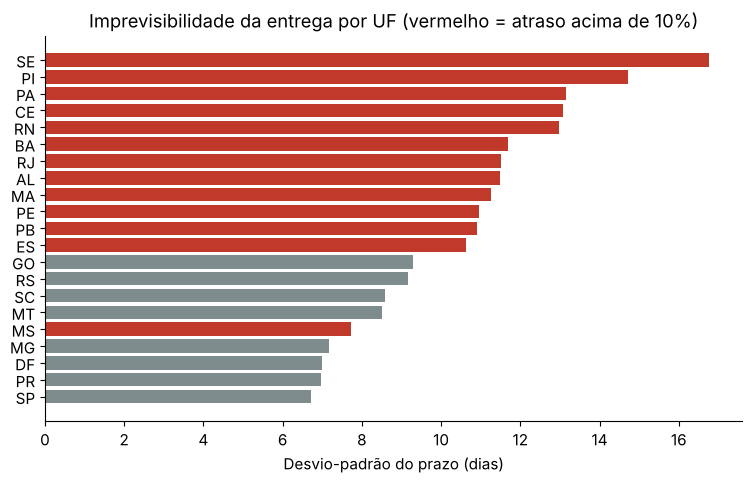

In [9]:
p=(df.order_delivered_customer_date-df.order_purchase_timestamp).dt.total_seconds()/86400
print('Prazo de entrega (dias): média {:.1f} | mediana {:.1f} | desvio-padrão {:.1f} | CV {:.2f} | P90 {:.1f} | máximo {:.0f} | assimetria {:.2f}'.format(p.mean(),p.median(),p.std(),p.std()/p.mean(),p.quantile(.9),p.max(),p.skew()))
print('Média > mediana e assimetria positiva: poucos pedidos muito demorados puxam a média para cima, por isso usamos a mediana como prazo típico.')
df['prazo_dias']=p
disp=df.groupby('customer_state').agg(pedidos=('order_id','size'),media=('prazo_dias','mean'),mediana=('prazo_dias','median'),desvio=('prazo_dias','std'),atraso=('atrasou','mean'))
disp['cv']=disp.desvio/disp.media
disp=disp[disp.pedidos>=300].sort_values('desvio',ascending=False)
print(disp.round(2).to_string())
print('Correlação entre desvio-padrão do prazo e taxa de atraso por UF: {:.2f}'.format(disp[['desvio','atraso']].corr().iloc[0,1]))
print('Correlação entre CV e taxa de atraso por UF: {:.2f}'.format(disp[['cv','atraso']].corr().iloc[0,1]))
fig,ax=plt.subplots(figsize=(9,5)); d=disp.sort_values('desvio')
ax.barh(d.index,d.desvio,color=['#c0392b' if v>.10 else '#7f8c8d' for v in d.atraso]); ax.set_xlabel('Desvio-padrão do prazo (dias)')
ax.set_title('Imprevisibilidade da entrega por UF (vermelho = atraso acima de 10%)')
fig.savefig(FIG/'05_desvio_prazo_uf.png',dpi=150,bbox_inches='tight'); plt.show()

## 8. Penetração por UF com dados externos (IBGE)
Fonte: IBGE, estimativas da população residente em 1º/07/2018 (DOU), arquivo `data/external/populacao_uf_2018_ibge.csv`.

Brasil: 46 pedidos por 100 mil habitantes no período
                populacao_2018  pedidos  pedidos_100mil  atraso
customer_state                                                 
AM                     4080611      145           3.553   0.041
RR                      576568       40           6.938   0.125
AP                      829494       67           8.077   0.045
AC                      869265       80           9.203   0.038
MA                     7035055      713          10.135   0.196
PA                     8513497      942          11.065   0.124
AL                     3322820      396          11.918   0.240
PB                     3996496      516          12.911   0.110
RN                     3479010      470          13.510   0.109
RO                     1757589      243          13.826   0.029
CE                     9075649     1273          14.027   0.154
PI                     3264531      475          14.550   0.160
SE                     2278308      332          14

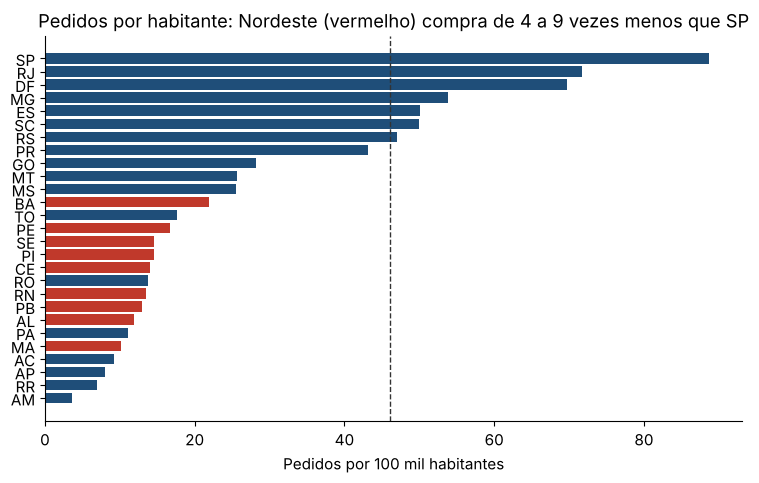

In [10]:
pop=pd.read_csv('../data/external/populacao_uf_2018_ibge.csv')
assert pop.populacao_2018.sum()==208494900
pen=df.groupby('customer_state').agg(pedidos=('order_id','size'),receita=('receita','sum'),atraso=('atrasou','mean')).join(pop.set_index('uf'))
pen['pedidos_100mil']=pen.pedidos/pen.populacao_2018*1e5
media_br=len(df)/pop.populacao_2018.sum()*1e5
print(f'Brasil: {media_br:.0f} pedidos por 100 mil habitantes no período')
print(pen.sort_values('pedidos_100mil')[['populacao_2018','pedidos','pedidos_100mil','atraso']].round(3).to_string())
ne=['MA','PI','CE','RN','PB','PE','AL','SE','BA']
pne=pen.loc[ne]; pen_ne=pne.pedidos.sum()/pne.populacao_2018.sum()*1e5
extra=(media_br-pen_ne)/1e5*pne.populacao_2018.sum(); ticket_ne=pne.receita.sum()/pne.pedidos.sum()
print(f'Nordeste: {pen_ne:.0f} pedidos/100 mil hab. (média Brasil {media_br:.0f}); SP: {pen.loc['SP','pedidos_100mil']:.0f}')
print(f'Cenário: se o Nordeste atingisse a média do Brasil, seriam ~{extra:,.0f} pedidos a mais no período (≈R$ {extra*ticket_ne/1e6:.1f} mi, ticket NE R$ {ticket_ne:.0f})')
print('Correlação penetração x atraso por UF: {:.2f}'.format(pen[['pedidos_100mil','atraso']].corr().iloc[0,1]))
fig,ax=plt.subplots(figsize=(9,5)); q=pen.sort_values('pedidos_100mil')
ax.barh(q.index,q.pedidos_100mil,color=['#c0392b' if u in ne else '#1f4e79' for u in q.index]); ax.axvline(media_br,color='#333',ls='--',lw=1)
ax.set_xlabel('Pedidos por 100 mil habitantes'); ax.set_title('Pedidos por habitante: Nordeste (vermelho) compra de 4 a 9 vezes menos que SP')
fig.savefig(FIG/'06_penetracao_uf.png',dpi=150,bbox_inches='tight'); plt.show()

## 9. Previsão de receita (set–dez/2018)
Validação: treinamos com jan/2017–abr/2018 e testamos em mai–ago/2018, comparando o erro percentual médio (MAPE) de quatro métodos simples.

Média dos últimos 3 meses         7.2
Ingênuo (último mês)             10.6
Holt com tendência amortecida    27.2
Tendência linear                 31.6
Modelos que extrapolam o crescimento de 2017 erram mais: a série estabilizou.
Base (média jun–ago/2018): R$ 853,885 | fator Black Friday (nov/2017 ÷ média out+dez/2017): 1.44
2018-09-01     854.0
2018-10-01     854.0
2018-11-01    1227.0
2018-12-01     854.0
Freq: MS
Receita prevista 2018: R$ 11.0 mi (jan–ago realizado R$ 7.2 mi + set–dez previsto R$ 3.8 mi), faixa ±7%


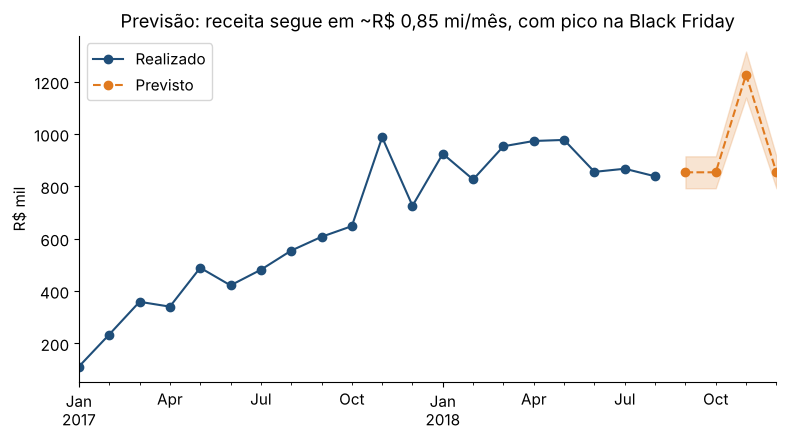

In [11]:
import warnings; warnings.filterwarnings('ignore')
from statsmodels.tsa.holtwinters import ExponentialSmoothing
s=m.receita.copy(); s.index=s.index.to_timestamp()
tr,te=s[:'2018-04'],s['2018-05':]
mape=lambda prev:(abs(np.asarray(prev)-te.values)/te.values).mean()*100
coef=np.polyfit(np.arange(len(tr)),tr.values,1)
res={'Ingênuo (último mês)':mape([tr.iloc[-1]]*4),'Média dos últimos 3 meses':mape([tr.iloc[-3:].mean()]*4),
     'Tendência linear':mape(np.polyval(coef,np.arange(len(tr),len(tr)+4))),
     'Holt com tendência amortecida':mape(ExponentialSmoothing(tr,trend='add',damped_trend=True).fit().forecast(4))}
print(pd.Series(res).round(1).sort_values().to_string()); print('Modelos que extrapolam o crescimento de 2017 erram mais: a série estabilizou.')
base=s.iloc[-3:].mean(); fator_bf=s['2017-11-01']/s[['2017-10-01','2017-12-01']].mean(); erro=min(res.values())/100
prev=pd.Series([base,base,base*fator_bf,base],index=pd.date_range('2018-09-01',periods=4,freq='MS'))
print(f'Base (média jun–ago/2018): R$ {base:,.0f} | fator Black Friday (nov/2017 ÷ média out+dez/2017): {fator_bf:.2f}')
print((prev/1e3).round(0).rename('previsão R$ mil').to_string())
tot=s['2018'].sum()+prev.sum(); print(f'Receita prevista 2018: R$ {tot/1e6:.1f} mi (jan–ago realizado R$ {s['2018'].sum()/1e6:.1f} mi + set–dez previsto R$ {prev.sum()/1e6:.1f} mi), faixa ±{erro:.0%}')
fig,ax=plt.subplots(); (s/1e3).plot(ax=ax,marker='o',color='#1f4e79',label='Realizado')
(prev/1e3).plot(ax=ax,marker='o',ls='--',color='#e07a1f',label='Previsto'); ax.fill_between(prev.index,prev/1e3*(1-erro),prev/1e3*(1+erro),color='#e07a1f',alpha=.2)
ax.set_ylabel('R$ mil'); ax.set_xlabel(''); ax.legend(); ax.set_title('Previsão: receita segue em ~R$ 0,85 mi/mês, com pico na Black Friday')
fig.savefig(FIG/'07_previsao_receita.png',dpi=150,bbox_inches='tight'); plt.show()